<a href="https://colab.research.google.com/github/NjehAbabio/ITAI2373-NewsBot-Midterm/blob/main/Midterm_NewsBot_Intelligence_System_EMMANUEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Student:** Emmanuel ABABIO ATTA NJEH — individual project
**Date:** October 17, 2026
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (business, entertainment, politics, sport, tech)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## Individual review and completion status

This review preserves the original code and saved outputs. Added **Student Task completion** cells provide the missing analyses. They have not been executed in this review environment; run them in Colab and inspect their results before checking the remaining boxes or submitting. Suggested first-person answers are examples to revise in your own words.

**Student:** Emmanuel ABABIO ATTA NJEH  
**Date:** October 17, 2026  
**GitHub repository:** [Insert your actual public repository URL]

### Evidence checked
- [x] Real BBC dataset loaded: 1,490 articles and five categories.
- [x] Original saved outputs show preprocessing, TF-IDF, POS, sentiment, classification and NER.
- [x] Three template demonstration articles processed successfully.
- [x] Answers to discussion and reflection questions added below.
- [ ] Run and review the added Student Task completion cells.
- [ ] Review the independent evaluation before reporting final model performance.
- [ ] Add your own test articles; the three existing examples came from the template.
- [ ] Add repository URL and verify repository organization and README.
- [ ] Personalize the journal example and verify its final two-page layout.
- [ ] Record the optional video if you choose to do it.

The full assignment requires dataset approval. Verify this separately. Group-only tasks are left out of the individual response.

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [2]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 94.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All packages installed successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [3]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

### Suggested response to the application question
An editorial assistant could use NewsBot to route incoming articles into desks and search for people, organizations and locations. A company could monitor coverage of its brand, while a university library could organize a searchable news collection. The value is faster retrieval and less repetitive sorting. Sentiment is a description of wording, not a measurement of public opinion; a newsroom should review uncertain results.

For this project, the target users are editors and media-monitoring analysts. The BBC dataset supports business, entertainment, politics, sport and tech. It does not provide a health category or article dates.

In [4]:
# Load the real BBC news dataset
df = pd.read_csv('/content/BBC News Train.csv')

# Match the column names used by this notebook
df = df.rename(columns={
    'ArticleId': 'article_id',
    'Text': 'content',
    'Category': 'category'
})

print("Total articles:", len(df))
print("\nArticles per category:")
print(df['category'].value_counts())

df.head()

Total articles: 1490

Articles per category:
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


,article_id,content,category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


In [5]:
# Data preparation template
import pandas as pd
import numpy as np

# 1. Examine your dataset
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nFirst few rows:")
print(df.head())

# 2. Identify text and category columns
# Adjust these column names based on your dataset
text_column = 'content'  # or 'description', 'content', 'headline', etc.
category_column = 'category'  # or 'label', 'class', etc.

# 3. Check for missing values
print(f"\nMissing values:")
print(df.isnull().sum())

# 4. Remove rows with missing text or categories
df_clean = df.dropna(subset=[text_column, category_column])

# 5. Check category distribution
print(f"\nCategory distribution:")
print(df_clean[category_column].value_counts())

# 6. Sample if dataset is too large (keep under 2000 for Colab)
if len(df_clean) > 2000:
    df_final = df_clean.sample(n=2000, random_state=42)
    print(f"\nSampled dataset to {len(df_final)} rows")
else:
    df_final = df_clean

# 7. Rename columns for consistency
df_final = df_final.rename(columns={
    text_column: 'content',
    category_column: 'category'
})

# 8. Save prepared dataset
df_final.to_csv('newsbot_dataset.csv', index=False)
print("\n✅ Dataset prepared and saved as 'newsbot_dataset.csv'")

Dataset Info:
Shape: (1490, 3)
Columns: ['article_id', 'content', 'category']

First few rows:
   article_id                                            content  category
0        1833  worldcom ex-boss launches defence lawyers defe...  business
1         154  german business confidence slides german busin...  business
2        1101  bbc poll indicates economic gloom citizens in ...  business
3        1976  lifestyle  governs mobile choice  faster  bett...      tech
4         917  enron bosses in $168m payout eighteen former e...  business

Missing values:
article_id    0
content       0
category      0
dtype: int64

Category distribution:
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

✅ Dataset prepared and saved as 'newsbot_dataset.csv'


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

📈 CATEGORY DISTRIBUTION
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


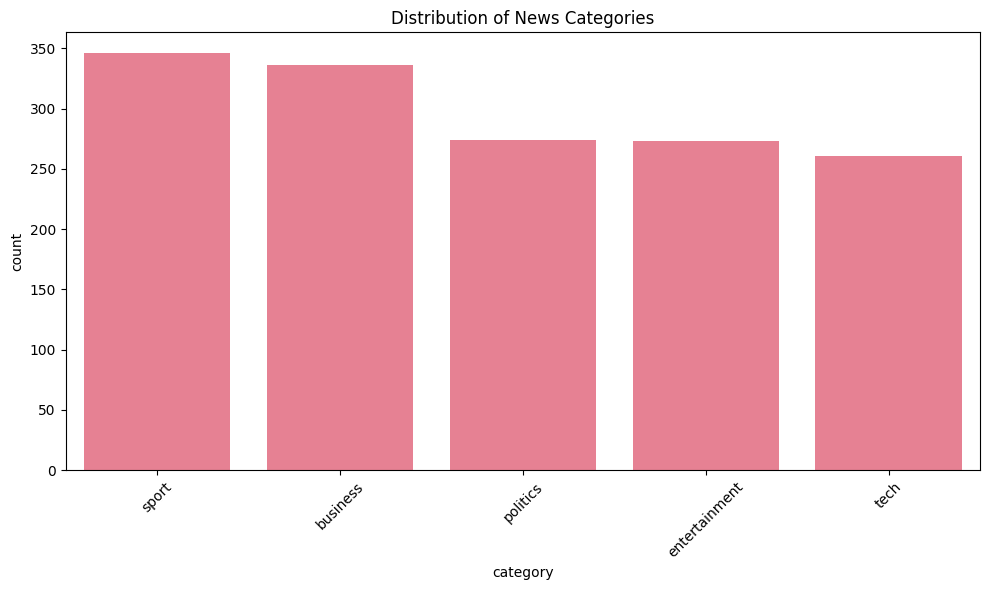

In [6]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
#print(f"Date range: {df['date'].min()} to {df['date'].max()}")
#print(f"Unique sources: {df['source'].nunique()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues

### Student Task completion for dataset exploration
The saved data-preparation output reports zero missing values and category counts of sport 346, business 336, politics 274, entertainment 273 and tech 261. The largest class is about 1.33 times the smallest, so imbalance is modest. The review's check on the actual CSV found **50 repeated article texts**, zero blank texts/labels and zero duplicate IDs. Mean article length is 385.01 whitespace-separated words, median 337, minimum 90 and maximum 3,345. Repeated text can leak across a random split; the independent classifier experiment below removes exact text duplicates before splitting. Source distribution is unavailable because the CSV has no source column; BBC is the dataset provenance, not a supplied per-row field.
- [x] Missing values checked in saved preparation output.
- [ ] Run length distribution and additional data-quality checks below.
- Source distribution: not applicable to available columns.

Missing values:
content     0
category    0
dtype: int64
Blank text / labels: 0 0
Exact duplicate article texts: 50
Duplicate article IDs: 0
Article lengths in whitespace-separated words:
count    1490.000000
mean      385.012752
std       210.898616
min        90.000000
25%       253.000000
50%       337.000000
75%       468.750000
max      3345.000000
Name: content, dtype: float64
Category percentages:
category
sport            23.22
business         22.55
politics         18.39
entertainment    18.32
tech             17.52
Name: proportion, dtype: float64


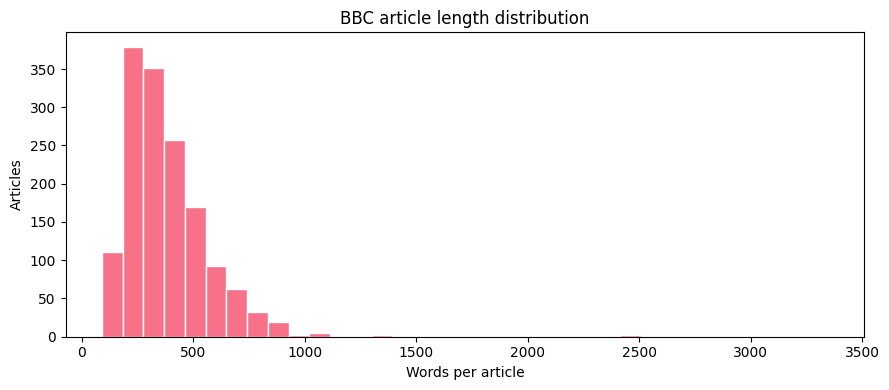

In [7]:
print("Missing values:")
print(df[['content', 'category']].isna().sum())
blank_text = df['content'].fillna('').str.strip().eq('')
blank_label = df['category'].fillna('').str.strip().eq('')
print("Blank text / labels:", int(blank_text.sum()), int(blank_label.sum()))
print("Exact duplicate article texts:", int(df['content'].duplicated().sum()))
print("Duplicate article IDs:", int(df['article_id'].duplicated().sum()))
article_lengths = df['content'].fillna('').str.split().str.len()
print("Article lengths in whitespace-separated words:")
print(article_lengths.describe())
print("Category percentages:")
print(df['category'].value_counts(normalize=True).mul(100).round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(article_lengths, bins=35, edgecolor='white')
ax.set(title='BBC article length distribution', xlabel='Words per article', ylabel='Articles')
plt.tight_layout()
plt.show()

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

### Suggested response on preprocessing
Cleaning reduces irrelevant variation from URLs, punctuation and extra spaces. Tokenization makes words available for analysis, stop-word removal reduces common terms, and lemmatization groups some related forms. Skipping all preprocessing can make the feature vocabulary noisier. However, preprocessing is task-dependent: sentiment needs negation and punctuation, and NER/POS need as much original wording and capitalization as the source provides. I therefore use processed text for TF-IDF and original `full_text` for sentiment, POS, syntax and NER. The supplied BBC text is already lowercase, which limits proper-noun and entity detection. The template lemmatizer uses its default noun setting, so it does not fully normalize every verb.

In [8]:
# Initialize preprocessing tools
nltk.download('punkt_tab')
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [9]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create new columns for processed text
#df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
#df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud ch...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...


### Student Task completion for preprocessing
Run the following measurements, then describe the actual reductions in your own words. Vocabulary counts below use the same simple alphabetic-token rule before and after so the comparison is explicit. A smaller vocabulary is a tradeoff, not automatic evidence of better accuracy.

In [10]:
before = df['full_text'].fillna('')
after_text = df['full_text_processed'].fillna('')
length_comparison = pd.DataFrame({
    'before': [before.str.len().mean(), before.str.split().str.len().mean()],
    'after': [after_text.str.len().mean(), after_text.str.split().str.len().mean()]
}, index=['Mean characters', 'Mean whitespace-separated words'])
print(length_comparison.round(2))
before_vocab = set()
after_counter = Counter()
for original, processed in zip(before, after_text):
    before_vocab.update(re.findall(r'[a-z]+', original.lower()))
    after_counter.update(re.findall(r'[a-z]+', processed.lower()))
print('Unique alphabetic tokens before:', len(before_vocab))
print('Unique alphabetic tokens after:', len(after_counter))
print('Most common processed words:', after_counter.most_common(20))
print('Empty processed articles:', int(after_text.str.strip().eq('').sum()))

                                  before    after
Mean characters                  2233.46  1481.36
Mean whitespace-separated words   385.01   207.01
Unique alphabetic tokens before: 23555
Unique alphabetic tokens after: 22486
Most common processed words: [('said', 4838), ('year', 1872), ('would', 1711), ('also', 1426), ('new', 1334), ('people', 1323), ('one', 1190), ('could', 1032), ('game', 949), ('time', 940), ('first', 893), ('last', 883), ('say', 844), ('two', 816), ('world', 811), ('film', 802), ('government', 771), ('make', 695), ('company', 682), ('firm', 675)]
Empty processed articles: 0


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [11]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


In [12]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0390
  company: 0.0371
  market: 0.0344
  bank: 0.0336
  year: 0.0334
  growth: 0.0332
  economy: 0.0317
  sale: 0.0316
  share: 0.0307
  profit: 0.0274

📰 TECH:
  mobile: 0.0513
  phone: 0.0468
  people: 0.0457
  technology: 0.0410
  game: 0.0381
  user: 0.0377
  service: 0.0369
  software: 0.0365
  computer: 0.0329
  net: 0.0308

📰 POLITICS:
  labour: 0.0648
  election: 0.0604
  blair: 0.0558
  party: 0.0538
  tory: 0.0463
  would: 0.0456
  government: 0.0455
  minister: 0.0427
  brown: 0.0384
  tax: 0.0330

📰 SPORT:
  game: 0.0448
  england: 0.0375
  win: 0.0342
  player: 0.0323
  match: 0.0304
  champion: 0.0293
  cup: 0.0278
  team: 0.0260
  chelsea: 0.0255
  injury: 0.0249

📰 ENTERTAINMENT:
  film: 0.1000
  award: 0.0524
  best: 0.0460
  show: 0.0376
  star: 0.0375
  music: 0.0357
  band: 0.0350
  actor: 0.0339
  year: 0.0300
  album: 0.0291


### Student Task completion for TF-IDF
The saved results identify `firm` as a leading business term, `mobile` in tech, `labour` in politics, `game` in sport and `film` in entertainment. These fit the subjects in the dataset. `game` appears in sport and technology, illustrating why a single keyword can be ambiguous. Frequent terms such as `year` are less specific. Mean TF-IDF ranks summarize category vocabulary; they are not causal feature importance. Run the plots below to compare both rankings and cross-category overlap.

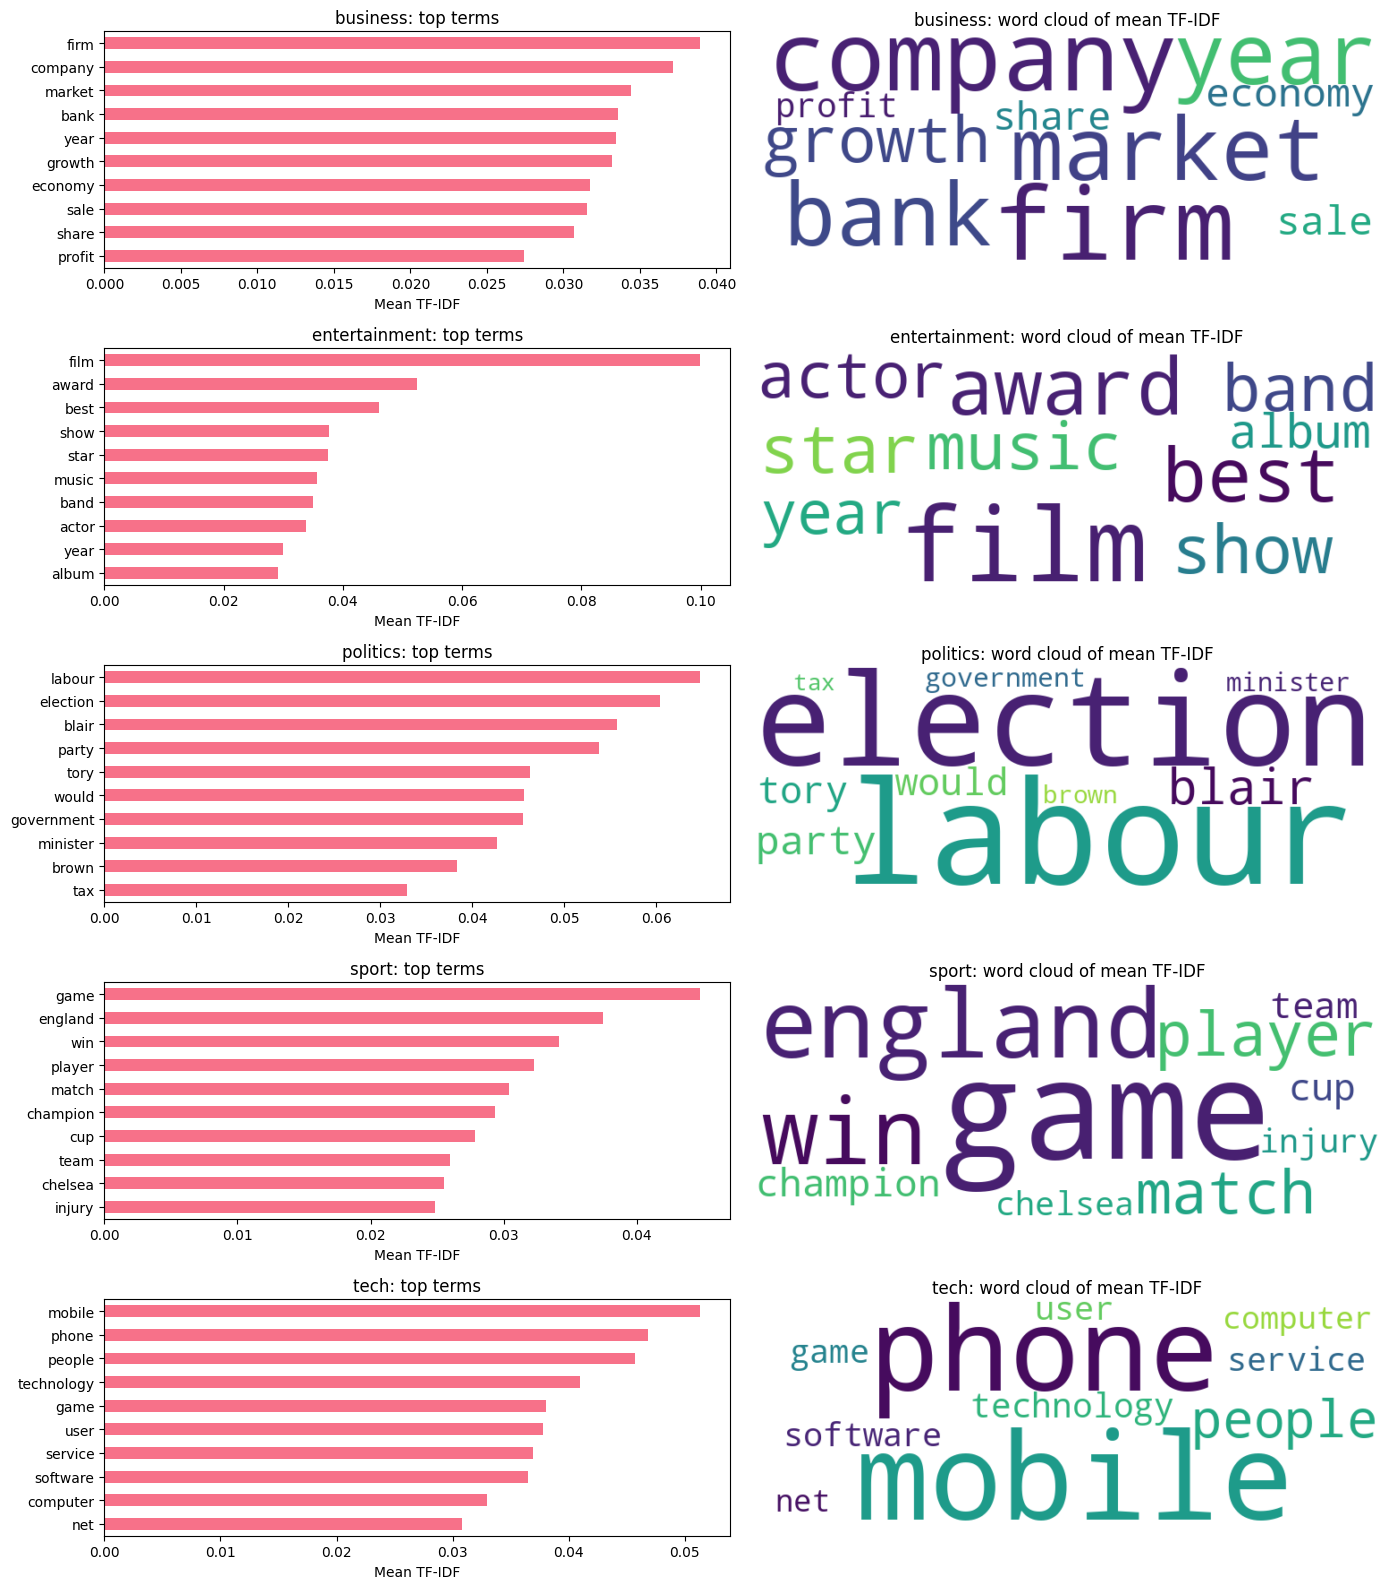

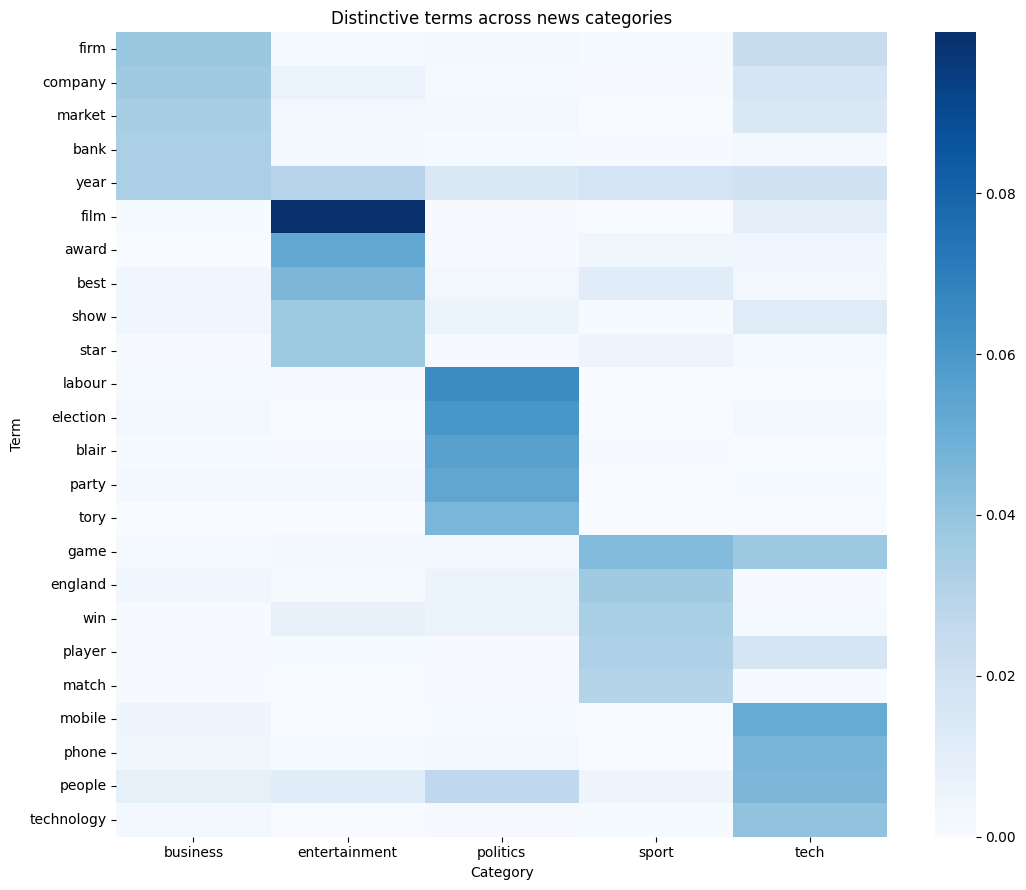

In [13]:
term_means = tfidf_df.drop(columns='category').groupby(tfidf_df['category']).mean()
fig, axes = plt.subplots(len(term_means), 2, figsize=(14, 3.2 * len(term_means)))
selected_terms = []
for row_idx, (category, means) in enumerate(term_means.iterrows()):
    top = means.nlargest(10)
    selected_terms.extend(top.index[:5])
    top.sort_values().plot.barh(ax=axes[row_idx, 0])
    axes[row_idx, 0].set(title=f'{category}: top terms', xlabel='Mean TF-IDF')
    cloud = WordCloud(width=700, height=260, background_color='white', random_state=42)
    axes[row_idx, 1].imshow(cloud.generate_from_frequencies(top.to_dict()), interpolation='bilinear')
    axes[row_idx, 1].set_title(f'{category}: word cloud of mean TF-IDF')
    axes[row_idx, 1].axis('off')
plt.tight_layout()
plt.show()
selected_terms = list(dict.fromkeys(selected_terms))
plt.figure(figsize=(11, 9))
sns.heatmap(term_means[selected_terms].T, cmap='Blues')
plt.title('Distinctive terms across news categories')
plt.xlabel('Category')
plt.ylabel('Term')
plt.tight_layout()
plt.show()

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [14]:
nltk.download('averaged_perceptron_tagger_eng')
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2241  0.0736  0.0011  0.0000  0.0333  0.0410  0.0200  0.0277   
entertainment  0.2454  0.0574  0.0008  0.0000  0.0281  0.0462  0.0194  0.0295   
politics       0.2087  0.0679  0.0007  0.0003  0.0455  0.0462  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0408  0.0457  0.0175  0.0247   
tech           0.1932  0.0855  0.0006  0.0000  0.0420  0.0299  0.0236  0.0270   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0223  0.0939  0.0024  0.0050  0.0286  0.0010  0.0010   
politics       0.0199  0.0224  0.0901  0.0032  0

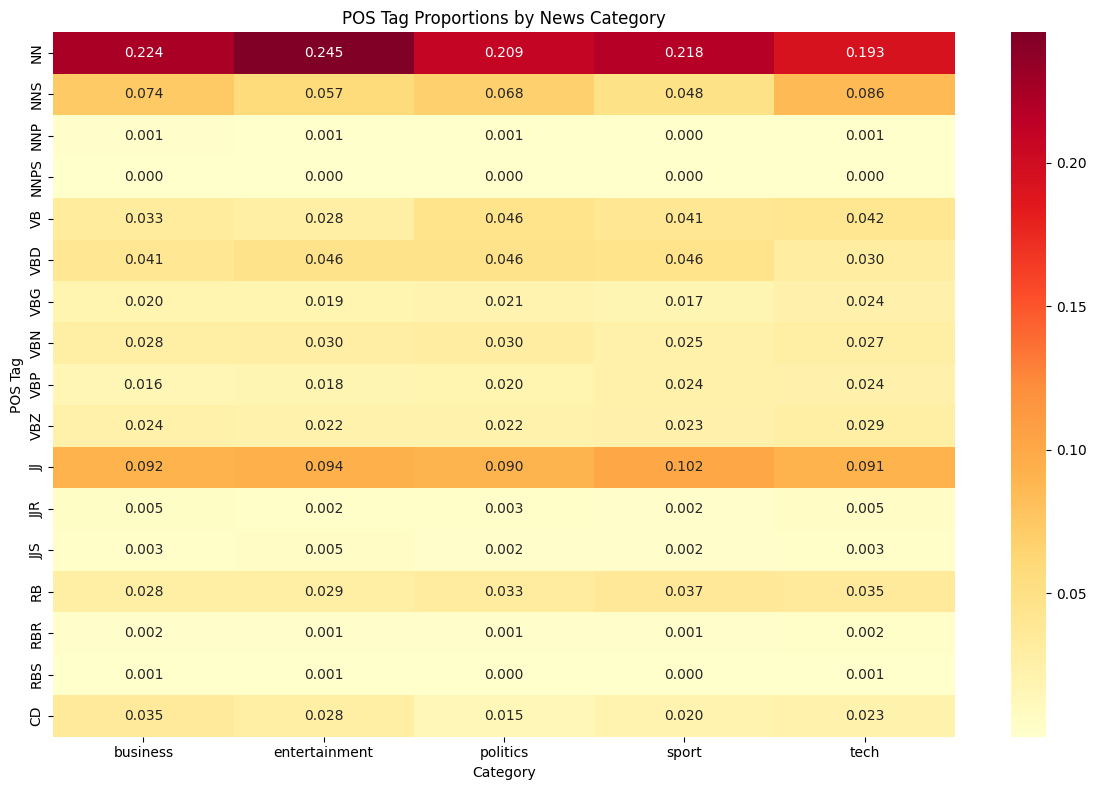


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [15]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

### Answers to the POS questions
1. **Proper nouns:** Business has the highest mean NNP + NNPS proportion, approximately 0.0011 (0.11%). All values are very low. The dataset is lowercase, so these are model outputs under a capitalization limitation, not a reliable count of all names.
2. **Action-related verb tags:** Using the question's VB + VBD + VBG definition, politics is highest at about 0.1126 (11.26%). Sport is about 10.40%; the proposed sports hypothesis is not supported by this measure. These grammatical tags do not guarantee an action meaning.
3. **Adjectives:** Sport has the highest JJ proportion, 10.15%, versus 9.01% in politics. This suggests somewhat more descriptive wording in sport, but no significance test was performed.
4. **Numbers:** Business has the highest CD proportion, 3.47%, followed by entertainment 2.78%, tech 2.28%, sport 2.03% and politics 1.47%. This is consistent with business reporting on prices and financial amounts.
5. **Nouns versus verbs:** Common-noun NN + NNS proportions are highest in entertainment (about 30.28%) and business (29.77%). Summing all six listed verb tags gives politics about 18.51%, the highest. These percentages are means per article, not pooled token totals.
- [x] POS questions answered from saved category statistics.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [16]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences: 

In [17]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b

### Student Task completion for syntax and relationships
The original parsing demonstration covers only the first five articles, four business articles and one tech article. It cannot establish cross-category differences. Run this balanced sample of up to ten articles per category to compare syntax and construct candidate features. Subject/action/object patterns below are dependency-based approximations, not a trained semantic-role labeler or verified facts. Missing dates prevent time-trend analysis.

Candidate syntax features, not added to the original classifier:
               tokens_per_sentence  mean_dependency_depth  \
category                                                    
business                   23.2083                 3.3655   
entertainment              24.5962                 3.6383   
politics                   22.2508                 3.4930   
sport                      20.1900                 2.7862   
tech                       22.7434                 3.4838   

               subordinate_clause_rate  
category                                
business                        0.0584  
entertainment                   0.0448  
politics                        0.0737  
sport                           0.0489  
tech                            0.0682  
business most common dependency relations: [('prep', 307), ('pobj', 298), ('det', 260), ('compound', 239), ('amod', 225)]
entertainment most common dependency relations: [('compound', 450), ('pobj', 412), ('prep', 409), 

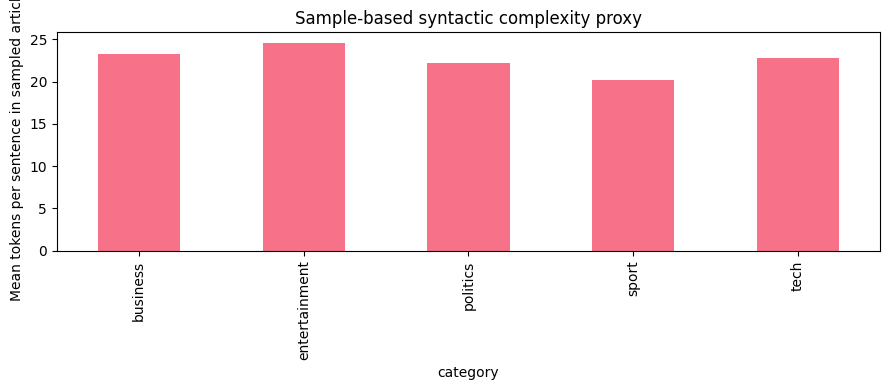

In [18]:
# Balanced sample keeps parsing manageable on Colab's free tier.
syntax_sample = pd.concat([
    group.sample(n=min(10, len(group)), random_state=42)
    for _, group in df.groupby('category')
])
syntax_records, action_records = [], []
dep_by_cat = defaultdict(Counter)
for (_, row), doc in zip(syntax_sample.iterrows(), nlp.pipe(syntax_sample['full_text'].astype(str), batch_size=10)):
    tokens = [t for t in doc if not t.is_space and not t.is_punct]
    sentences = list(doc.sents)
    depths = [sum(1 for _ in t.ancestors) for t in tokens]
    dep_by_cat[row['category']].update(t.dep_ for t in tokens)
    syntax_records.append({
        'article_id': row['article_id'], 'category': row['category'],
        'tokens_per_sentence': len(tokens) / max(1, len(sentences)),
        'mean_dependency_depth': np.mean(depths) if depths else 0,
        'subordinate_clause_rate': sum(t.dep_ in {'ccomp', 'xcomp', 'advcl', 'relcl'} for t in tokens) / max(1, len(tokens))
    })
    for verb in doc:
        if verb.pos_ != 'VERB':
            continue
        subjects = [c.text for c in verb.children if c.dep_ in {'nsubj', 'nsubjpass'}]
        objects = [c.text for c in verb.children if c.dep_ in {'dobj', 'obj', 'attr', 'oprd'}]
        if subjects:
            action_records.append({'category': row['category'], 'article_id': row['article_id'],
                'subject': ', '.join(subjects), 'verb': verb.lemma_,
                'object_or_complement': ', '.join(objects),
                'passive_subject': any(c.dep_ == 'nsubjpass' for c in verb.children)})
syntax_feature_df = pd.DataFrame(syntax_records)
print('Candidate syntax features, not added to the original classifier:')
print(syntax_feature_df.groupby('category').mean(numeric_only=True).drop(columns='article_id').round(4))
for category, counts in dep_by_cat.items():
    print(category, 'most common dependency relations:', counts.most_common(5))
print('Sample dependency-based action patterns:')
print(pd.DataFrame(action_records).head(15).to_string(index=False))
syntax_feature_df.groupby('category')['tokens_per_sentence'].mean().plot.bar(figsize=(9, 4))
plt.ylabel('Mean tokens per sentence in sampled articles')
plt.title('Sample-based syntactic complexity proxy')
plt.tight_layout()
plt.show()

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [19]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    #title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        #'title_sentiment': title_sentiment['compound'],
        #'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1490 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  business         -0.9701   negative
1  business          0.7623   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2404  0.8370 -0.9985  0.9995    0.0926    0.8370   
entertainment         0.5991  0.6796 -0.9978  0.9999    0.1356    0.8107   
politics              0.0578  0.8811 -0.9984  0.9999    0.0947    0.8184   
sport                 0.5541  0.7244 -0.9967  0.9996    0.1360    0.7933   
tech                  0.5233  0.7557 -0.9991  0.9993    0.0895    0.8598   

              neg_score  
                   mean  
category                 
business         0.0704  
entertainment    0.0537  
politics         0.0869  
sport            0.0707  
tech             0.0507  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

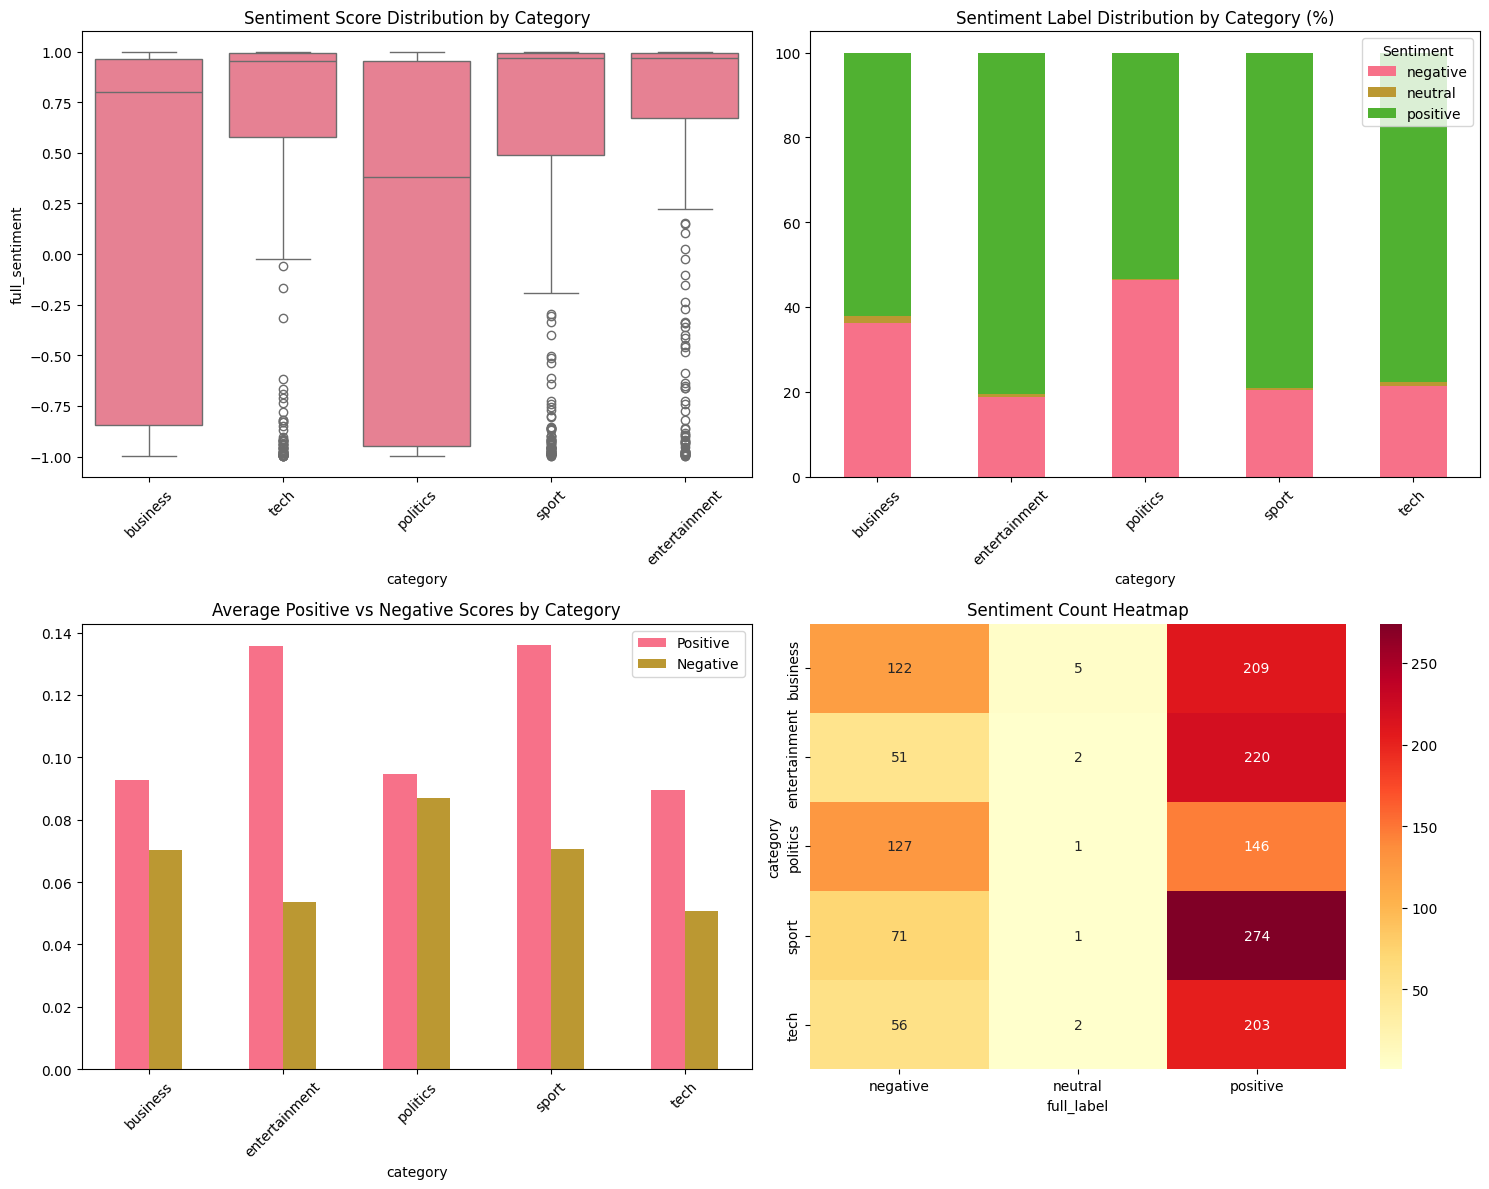

In [20]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

### Answers to the sentiment Student Task
- **Most positive and least positive:** Entertainment has the highest mean VADER compound score (0.5991) and 80.59% positive labels. Politics has the lowest mean (0.0578) and the highest negative-label share (46.35%). Calling politics the most negative category is relative: its mean is still slightly positive.
- **Title versus content:** This cannot be compared because BBC supplies no separate title field. Here `full_text` equals `content`, so their scores are identical.
- **Variation within categories:** Politics has the largest standard deviation (0.8811), followed by business (0.8370). Every category spans strongly negative to strongly positive scores. A category mean conceals this spread.
- **Classification feature:** The original model combines four sentiment scores with TF-IDF. This establishes use, not benefit. The independent experiment below compares feature sets using training-only cross-validation.
- **Limitations:** VADER estimates wording polarity, not truth, author intent, reader emotion or public opinion. The climate example scores +0.103 despite alarming language. Sentiment polarity is not a full emotion taxonomy.
- [x] Sentiment questions answered from saved statistics and test output.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [21]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
#length_features = np.array([
    #df['full_text'].str.len(),  # Character length
    #df['full_text'].str.split().str.len(),  # Word count
    #df['title'].str.len(),  # Title length
#]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    #length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1490, 5004)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1192 samples
  Test set: 298 samples


In [22]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
from sklearn.preprocessing import MinMaxScaler
classifiers = {
    'Naive Bayes': Pipeline([
    ('scaler', MinMaxScaler(clip=True)),
    ('classifier', MultinomialNB())
]),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.9664
  📊 CV Score: 0.9622 (+/- 0.0218)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.9732
  📊 CV Score: 0.9488 (+/- 0.0331)

🔄 Training SVM...
  ✅ Accuracy: 0.9564
  📊 CV Score: 0.9329 (+/- 0.0441)

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.9664   0.9622  0.0109
1  Logistic Regression         0.9732   0.9488  0.0165
2                  SVM         0.9564   0.9329  0.0220

🥇 Best performing model: Logistic Regression


📊 DETAILED EVALUATION: Logistic Regression

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.94      1.00      0.97        67
entertainment       0.98      1.00      0.99        55
     politics       1.00      0.93      0.96        55
        sport       0.99      1.00      0.99        69
         tech       0.96      0.92      0.94        52

     accuracy                           0.97       298
    macro avg       0.97      0.97      0.97       298
 weighted avg       0.97      0.97      0.97       298



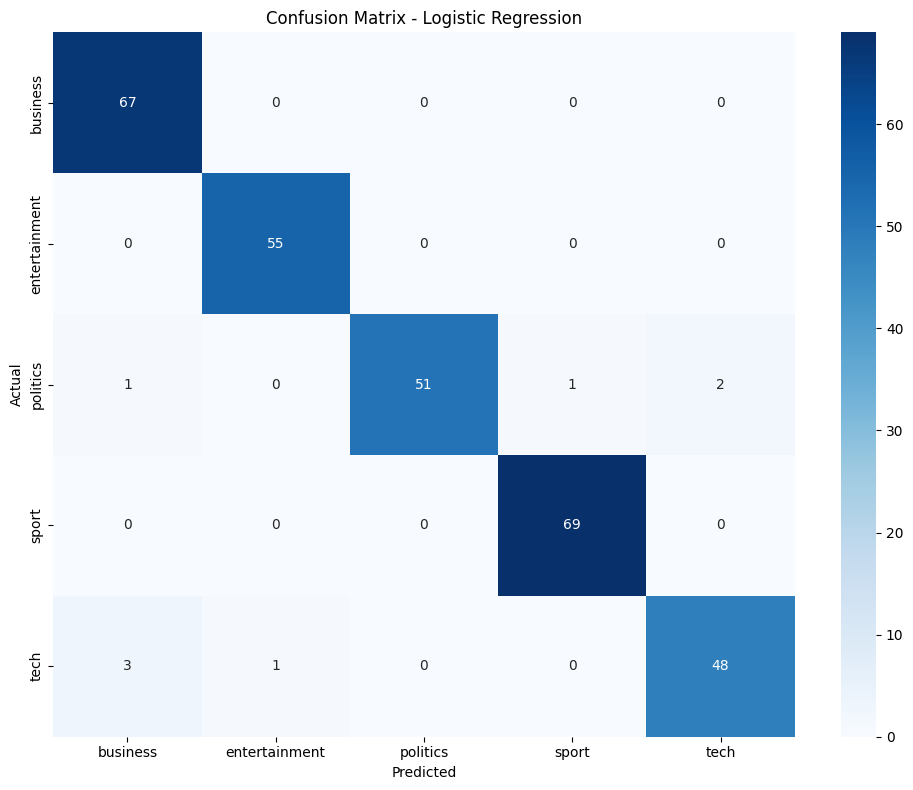


🔍 Top Features by Category:

📰 business:
  firm: 2.0299
  company: 1.7917
  bank: 1.7840
  market: 1.5161
  share: 1.4955
  economy: 1.4418
  profit: 1.3521
  economic: 1.3268
  price: 1.2846
  growth: 1.2485

📰 entertainment:
  film: 3.3049
  show: 1.9909
  star: 1.7161
  music: 1.7087
  album: 1.6792
  band: 1.6113
  singer: 1.5718
  actor: 1.4096
  song: 1.2882
  award: 1.2684

📰 politics:
  party: 2.1746
  labour: 2.0993
  blair: 2.0034
  election: 1.8973
  minister: 1.5311
  government: 1.5079
  tory: 1.3649
  lord: 1.3549
  would: 1.1533
  secretary: 1.0947

📰 sport:
  match: 1.5077
  champion: 1.4878
  england: 1.3758
  player: 1.3065
  coach: 1.2850
  cup: 1.2845
  game: 1.2590
  chelsea: 1.2437
  win: 1.1713
  club: 1.1334

📰 tech:
  computer: 1.7847
  game: 1.7810
  software: 1.7591
  user: 1.6501
  technology: 1.6009
  mobile: 1.5930
  net: 1.3759
  phone: 1.3656
  people: 1.3444
  site: 1.3256


In [23]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

### Student Task completion for classifier improvement
Saved original test accuracies are Naive Bayes 96.64%, Logistic Regression 97.32% and SVM 95.64%. Original TF-IDF was fitted before the train/test split, so test documents influenced the vocabulary and IDF. These are preliminary results; original cross-validation also reused the fitted vocabulary. Original model selection used test accuracy, so the same test set was not an untouched final evaluation.

The independent experiment below fixes the feature-fitting sequence without replacing your original working pipeline. It selects feature configuration and regularization using training-only cross-validation, then evaluates the selected pipeline once on the held-out split. Because this split has already appeared in notebook development, it is not a new independent external test. A new external test set is still desirable.

This experiment compares TF-IDF alone with TF-IDF plus actual sentiment and log-length features, tunes unigrams versus bigrams and regularization, and reports per-class metrics and a majority baseline. Modest imbalance is monitored through macro F1 and stratified splits. No benefit from added features is claimed until this cell runs.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score

# Rebuild aligned features explicitly by article ID.
evaluation_data = df[['article_id', 'full_text', 'full_text_processed', 'category']].merge(
    sentiment_df[['article_id', 'full_sentiment', 'pos_score', 'neu_score', 'neg_score']],
    on='article_id', how='left', validate='one_to_one'
)
evaluation_data['log_char_length'] = np.log1p(evaluation_data['full_text'].str.len())
evaluation_data['log_word_count'] = np.log1p(evaluation_data['full_text'].str.split().str.len())
# Identical articles must not appear in both training and held-out data.
evaluation_data = evaluation_data.drop_duplicates(subset='full_text').copy()
print('Articles after exact-text deduplication:', len(evaluation_data))
numeric_columns = ['full_sentiment', 'pos_score', 'neu_score', 'neg_score', 'log_char_length', 'log_word_count']
train_rows, holdout_rows = train_test_split(
    evaluation_data, test_size=0.2, random_state=42, stratify=evaluation_data['category'])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
candidate_searches = {}
for configuration in ['TF-IDF only', 'TF-IDF plus sentiment and lengths']:
    transformers = [('text', TfidfVectorizer(max_features=5000, min_df=2, max_df=0.8), 'full_text_processed')]
    if configuration != 'TF-IDF only':
        transformers.append(('numeric', StandardScaler(), numeric_columns))
    candidate = Pipeline([
        ('features', ColumnTransformer(transformers)),
        ('model', LogisticRegression(max_iter=2000, random_state=42))
    ])
    search = GridSearchCV(candidate, {
        'features__text__ngram_range': [(1, 1), (1, 2)],
        'model__C': [0.5, 1.0, 2.0]
    }, cv=cv, scoring='f1_macro', n_jobs=1, error_score='raise')
    search.fit(train_rows, train_rows['category'])
    candidate_searches[configuration] = search
    print(configuration, 'best CV macro F1:', round(search.best_score_, 4), search.best_params_)
selected_configuration = max(candidate_searches, key=lambda name: candidate_searches[name].best_score_)
audited_model = candidate_searches[selected_configuration].best_estimator_
audited_predictions = audited_model.predict(holdout_rows)
print('Selected using training CV:', selected_configuration)
print('Held-out accuracy:', accuracy_score(holdout_rows['category'], audited_predictions))
print('Held-out macro F1:', f1_score(holdout_rows['category'], audited_predictions, average='macro'))
majority = train_rows['category'].mode().iloc[0]
print('Majority baseline accuracy:', (holdout_rows['category'] == majority).mean())
print(classification_report(holdout_rows['category'], audited_predictions))
# Keep best_model/newsbot unchanged; this audit is a separate experiment.

Articles after exact-text deduplication: 1440
TF-IDF only best CV macro F1: 0.9728 {'features__text__ngram_range': (1, 1), 'model__C': 2.0}
TF-IDF plus sentiment and lengths best CV macro F1: 0.9373 {'features__text__ngram_range': (1, 1), 'model__C': 2.0}
Selected using training CV: TF-IDF only
Held-out accuracy: 0.9548611111111112
Held-out macro F1: 0.9535151116542853
Majority baseline accuracy: 0.2361111111111111
               precision    recall  f1-score   support

     business       0.93      0.99      0.96        67
entertainment       1.00      0.94      0.97        53
     politics       0.96      0.92      0.94        53
        sport       0.93      1.00      0.96        68
         tech       0.98      0.89      0.93        47

     accuracy                           0.95       288
    macro avg       0.96      0.95      0.95       288
 weighted avg       0.96      0.95      0.95       288



## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [25]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 42031
📰 Articles processed: 1490

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8799
PERSON         8015
CARDINAL       6184
GPE            5562
ORG            4427
NORP           2709
MONEY          1783
ORDINAL        1659
PERCENT        1276
TIME            592
LOC             504
QUANTITY        199
FAC              90
PRODUCT          87
LANGUAGE         61
EVENT            43
LAW              33
WORK_OF_ART       8
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1036  2413      3   10  1545         1   15  166    906   
entertainment      1110  1739     12   15   792         9    4   64    384   
politics            823  1359     22   23   944        10    4  120    235   
sport              1798  1978      5   40  1505        11    5   33     44   
tech               1417  1310      1    2   776     

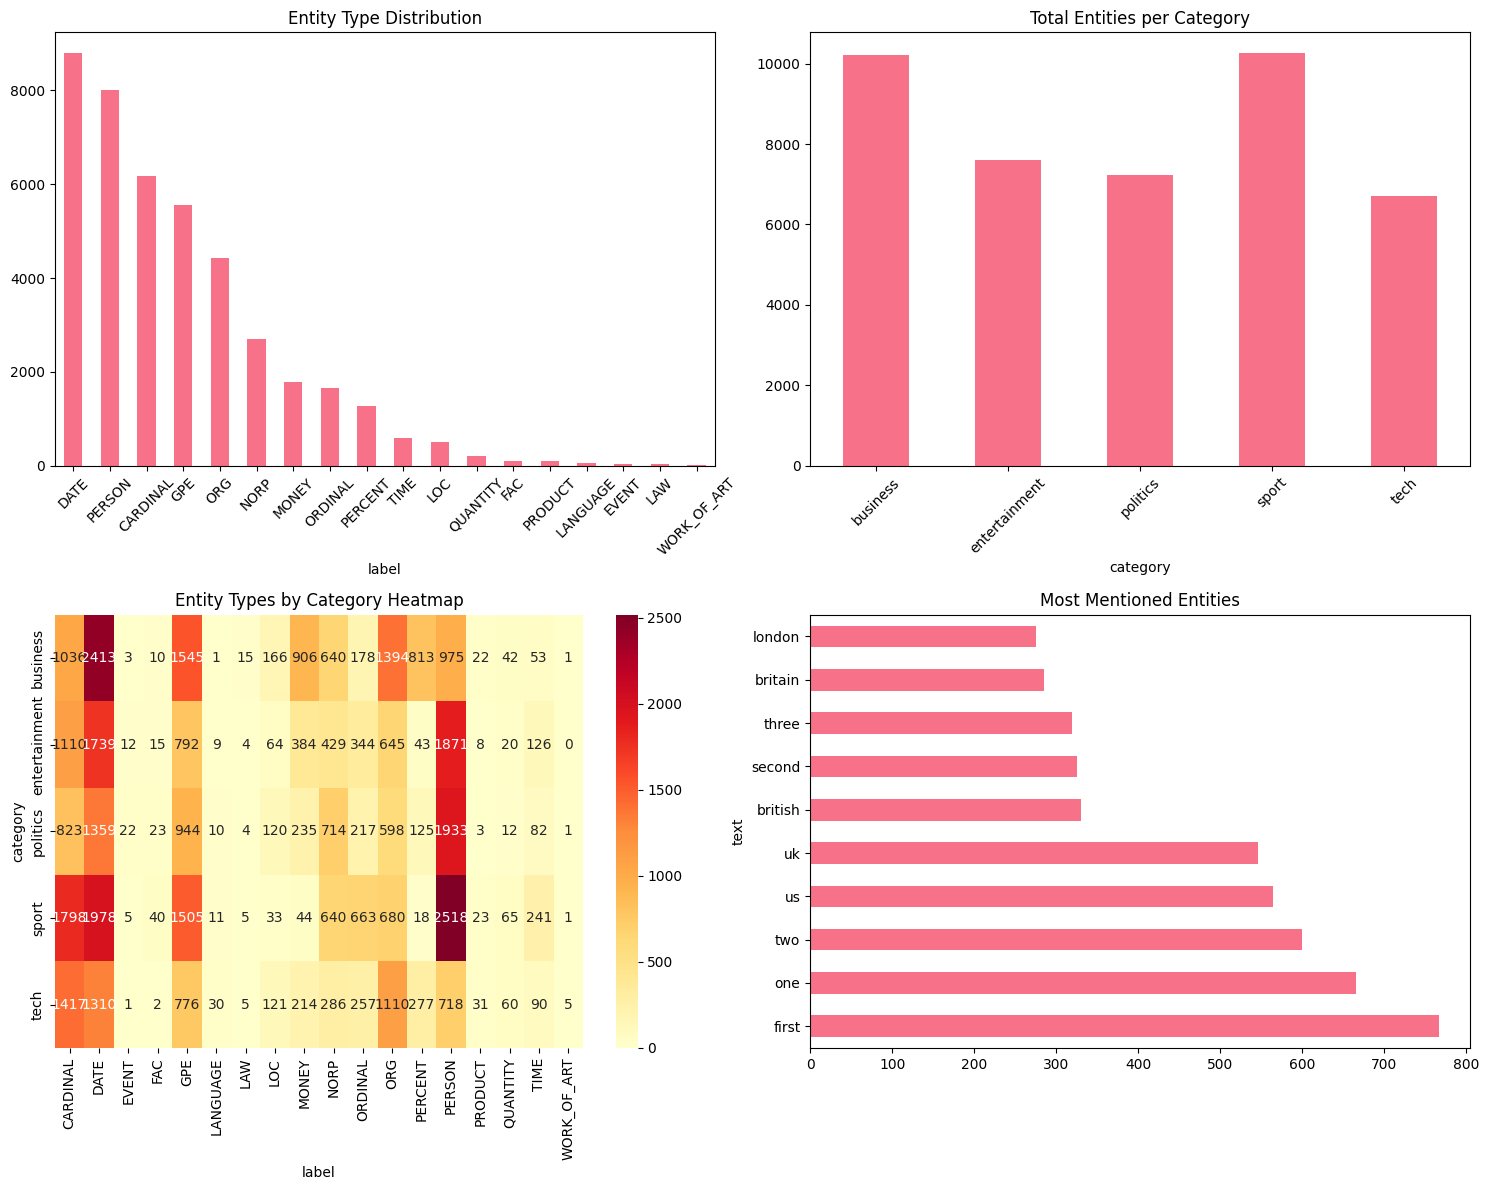

In [26]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

### Student Task completion for entity relationships
Saved outputs contain 42,031 entity mentions and 12,071 unique surface strings. DATE is the most frequent type (8,799), followed by PERSON (8,015). Business contains 906 MONEY mentions versus sport's 44. These are raw counts, affected by category size and article length. The code below also normalizes by articles and constructs co-occurrence edges.

Co-occurrence means two entities appeared in the same article; it does not establish a real-world relationship. Entity-associated article sentiment describes the surrounding article, not sentiment directed at that entity. Entity mentions over time are **not applicable** because no article date column exists. Dates found inside articles cannot safely stand in for publication dates.

The final demonstrations show extraction errors: `Microsoft Acquires` is labeled ORG, and a long climate headline plus `Scientists` becomes one ORG span. Lowercase source text and joining a title directly to its first sentence can affect extraction.

Top article-level co-occurrences:
      entity_a   entity_b  shared_articles
       britain         uk               74
        london         uk               67
            uk         us               65
         blair tony blair               53
       britain tony blair               39
      new york         us               32
         blair    britain               31
        france   scotland               30
    tony blair         uk               30
           bbc         uk               30
       britain     london               29
michael howard tony blair               29
       england   scotland               29
       england     france               29
           bbc    britain               27


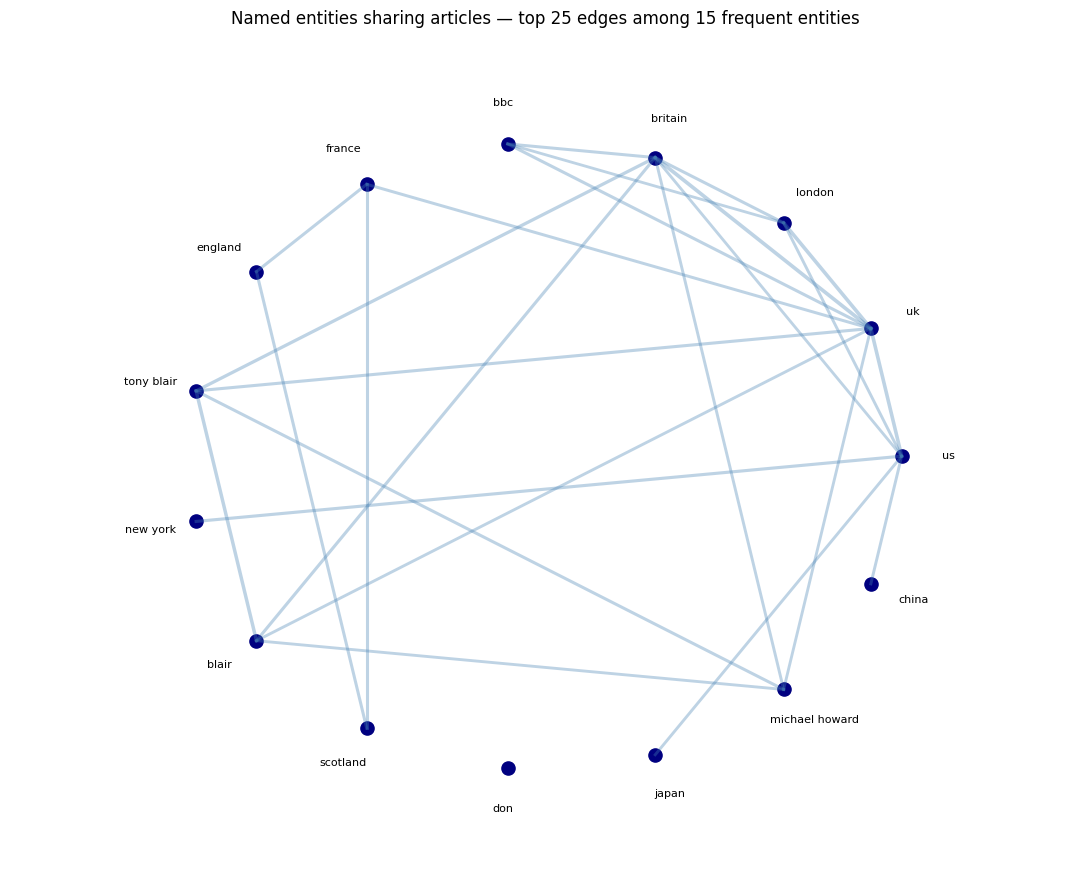

Mean entity mentions per article by category:
label          PERSON   ORG   GPE  DATE  MONEY
category                                      
business         2.90  4.15  4.60  7.18   2.70
entertainment    6.85  2.36  2.90  6.37   1.41
politics         7.05  2.18  3.45  4.96   0.86
sport            7.28  1.97  4.35  5.72   0.13
tech             2.75  4.25  2.97  5.02   0.82
Article sentiment associated with entities appearing in at least 5 articles:
                count   mean
entity_key                  
us                311  0.335
uk                305  0.433
london            183  0.447
britain           170  0.339
bbc               145  0.437
france            118  0.653
england           105  0.555
tony blair         90  0.158
new york           79  0.342
blair              70  0.095
don                66  0.444
scotland           66  0.521
japan              61  0.509
michael howard     61 -0.020
china              59  0.418


In [29]:
from itertools import combinations
# Restrict the graph to 15 frequent named entities to avoid an unreadable network.
named_entities = entities_df[entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])].copy()
named_entities['entity_key'] = named_entities['text'].str.lower().str.strip()
named_entities = named_entities.drop_duplicates(['article_id', 'entity_key'])
top_names = named_entities['entity_key'].value_counts().head(15).index.tolist()
edge_counts = Counter()
for _, group in named_entities[named_entities['entity_key'].isin(top_names)].groupby('article_id'):
    edge_counts.update(combinations(sorted(set(group['entity_key'])), 2))
edge_df = pd.DataFrame([(a, b, count) for (a, b), count in edge_counts.most_common()],
                       columns=['entity_a', 'entity_b', 'shared_articles'])
print('Top article-level co-occurrences:')
print(edge_df.head(15).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 9))
positions = {name: (np.cos(2*np.pi*i/max(1,len(top_names))), np.sin(2*np.pi*i/max(1,len(top_names))))
             for i, name in enumerate(top_names)}
for (a, b), count in edge_counts.most_common(25):
    xa, ya = positions[a]; xb, yb = positions[b]
    ax.plot([xa, xb], [ya, yb], color='steelblue', alpha=0.35, linewidth=0.5 + np.log1p(count)/2)
for name, (x, y) in positions.items():
    ax.scatter([x], [y], s=90, color='navy')
    ax.text(x*1.13, y*1.13, name, ha='center', va='center', fontsize=8)
ax.set_title('Named entities sharing articles — top 25 edges among 15 frequent entities')
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.35, 1.35); ax.axis('off')
plt.tight_layout(); plt.show()
normalized_entities = entity_by_category.div(df['category'].value_counts(), axis=0)
print('Mean entity mentions per article by category:')
print(normalized_entities[['PERSON', 'ORG', 'GPE', 'DATE', 'MONEY']].round(2))
entity_sentiments = named_entities.merge(
    sentiment_df[['article_id', 'full_sentiment']], on='article_id', validate='many_to_one')
association = entity_sentiments.groupby('entity_key')['full_sentiment'].agg(['count', 'mean'])
print('Article sentiment associated with entities appearing in at least 5 articles:')
print(association[association['count'] >= 5].sort_values('count', ascending=False).head(15).round(3))

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [30]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1490
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2233 characters
  Average Words per Article: 385 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Logistic Regression
  Best Accuracy: 0.9732

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3950

🔍 ENTITY INSIGHTS:
  Total Entities: 42031
  Unique Entities: 12071
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - may need balance

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [31]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text, full_text):
        """Classify using the same feature order as training."""

        # TF-IDF features
        features = self.vectorizer.transform([processed_text])

        # Calculate actual sentiment from the original text
        scores = self.analyze_sentiment(full_text)
        sentiment_features = np.array([[
            scores['compound'],
            scores['pos'],
            scores['neu'],
            scores['neg']
        ]])

        # Match training: TF-IDF followed by four sentiment features
        features_combined = np.hstack([
            features.toarray(),
            sentiment_features
        ])

        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        class_probs = dict(zip(
            self.classifier.classes_,
            probabilities
        ))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text, full_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [32]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: tech (37.42% confidence)

📊 Category Probabilities:
  tech: 0.374
  business: 0.251
  sport: 0.127
  entertainment: 0.127
  politics: 0.120

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment detected (0.

### Answers on system strengths and weaknesses
The three saved demonstrations are fictional examples supplied by the template, not verified reports of actual events or my own new test set.

| Example | Saved prediction | Interpretation |
|---|---|---|
| Microsoft acquisition | tech, 37.42% | Plausible overlap with business; manual review is appropriate. |
| Lakers championship | sport, 69.03% | The clearest topical match of the three, but below the prototype's 80% review threshold. |
| Climate report | politics, 25.97% | Very uncertain; the model must choose among five labels and has no environment class. VADER's +0.103 score is questionable for the alarming wording. |

The pipeline integrates text, entities and sentiment, but a successful run does not establish prediction correctness. Confidence values are model probabilities, not guarantees. Better coverage needs more diverse full-length articles, checks for unfamiliar subjects, entity-error review and an evaluation that fits features within training folds.

### Student Task completion for additional tests
These new short **synthetic** examples are provided for practice; personalize or replace them with your own independently sourced articles and cite any sources. Run the next cell and judge the results; do not claim it ran until you inspect its output. Expected labels are human test expectations, not ground truth for an external benchmark.

In [33]:
additional_tests = [
    ('business', 'Bank reports rising profits', 'The bank reported higher annual profit as lending revenue increased. Its directors proposed a larger dividend for shareholders.'),
    ('entertainment', 'Film wins major award', 'The film won the best picture award at the festival. The director thanked the actors, and critics praised the screenplay and soundtrack.'),
    ('politics', 'Parliament debates election reform', 'The government introduced an election reform bill in parliament. Opposition leaders challenged the proposal during a debate before the vote.'),
    ('sport', 'Football team wins cup final', 'The football team won the cup final after its striker scored twice. The coach praised the players and supporters after the match.'),
    ('tech', 'Software update adds security features', 'The software company released a security update for its mobile operating system. Users can install the update to protect their phones and applications.'),
    ('ambiguous business or tech', 'Game studio announces acquisition', 'A software company bought a video game studio. Investors welcomed the deal, while developers discussed the new graphics technology.'),
    ('outside available categories', 'Researchers study coastal habitats', 'Marine scientists surveyed coastal wetlands and recorded changes in wildlife populations. The study describes habitat loss and proposes conservation measures.')
]
for expected, title, content in additional_tests:
    output = newsbot.process_article(title, content)
    print(title)
    print('Expected or test condition:', expected)
    print('Predicted:', output['predicted_category'], 'probability:', round(output['category_confidence'], 3))
    print('Sentiment:', output['sentiment']['sentiment_label'], 'entities:', len(output['entities']))
    print()

Bank reports rising profits
Expected or test condition: business
Predicted: business probability: 0.758
Sentiment: positive entities: 1

Film wins major award
Expected or test condition: entertainment
Predicted: entertainment probability: 0.912
Sentiment: positive entities: 0

Parliament debates election reform
Expected or test condition: politics
Predicted: politics probability: 0.679
Sentiment: negative entities: 1

Football team wins cup final
Expected or test condition: sport
Predicted: sport probability: 0.92
Sentiment: positive entities: 0

Software update adds security features
Expected or test condition: tech
Predicted: tech probability: 0.646
Sentiment: positive entities: 1

Game studio announces acquisition
Expected or test condition: ambiguous business or tech
Predicted: tech probability: 0.547
Sentiment: positive entities: 0

Researchers study coastal habitats
Expected or test condition: outside available categories
Predicted: business probability: 0.313
Sentiment: negative

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [ ] **Module 5:** Parsing demonstration runs; execute the added cross-category relationship analysis.
- [x] **Module 6:** Sentiment polarity analyzed; distinct emotion classification remains an extension.
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [x] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [x] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [x] Integrated system demonstration

### 📈 Visualizations
- [x] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [x] POS pattern heatmaps
- [x] Sentiment distribution by category
- [x] Confusion matrix for classification
- [x] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [x] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*

## Individual reflection answer examples

Revise these suggested answers so the final reflection expresses your own experience and choices. Group collaboration is omitted because this project was completed individually.

**1 Technical mastery**
The hardest part was making the NLP components agree on their inputs and outputs. The missing NLTK resources and unavailable BBC columns stopped execution even though much of the template was correct. TF-IDF with classification was especially useful because it converted articles into category predictions; NER made articles searchable by names and organizations.

**2 Integration challenges**
I loaded the BBC CSV directly and renamed `ArticleId`, `Text` and `Category` to `article_id`, `content` and `category`. I removed references to unavailable title, date and source fields. I downloaded `punkt_tab` and `averaged_perceptron_tagger_eng`, used a MinMaxScaler pipeline for Naive Bayes's nonnegative-input requirement, and changed prediction features from seven dummy values to four calculated sentiment values. Both training and prediction then used 5,004 features. I learned to follow the traceback and correct the specific mismatch rather than replace unrelated code.

**3 Business applications**
NewsBot could help editors route stories, analysts retrieve articles about organizations, and libraries organize news collections. The low-confidence examples show that human review should remain part of the workflow. This is a prototype; its saved accuracy alone does not establish production readiness.

**4 Ethical considerations**
Wrong labels can hide relevant news, incorrect entities can associate people with the wrong events, and polarity scores can misrepresent serious reporting. The climate example illustrates that positive wording scores can conflict with human interpretation. I would communicate uncertainty, keep article sources visible, audit errors and avoid treating predictions as verified facts or public opinion.

**5 Future learning**
A possible next step is topic modeling to discover subjects beyond the five category labels. Transformer embeddings and context-aware sentiment models are also useful directions. First I would improve evaluation by fitting vectorization within training folds, testing on independently collected news and measuring whether additional features actually help.

**6 Team collaboration**
Not applicable to this individual project. No group roles, meetings or peer contributions are claimed.

**7 Portfolio value**
I can present the notebook, setup instructions, results, visualizations and examples in my public GitHub portfolio. I would explain the problems I diagnosed, show both successful and uncertain outputs, cite the dataset and libraries, and distinguish the original template from my changes and AI-assisted debugging. I should add my actual repository URL before submission.

## Remaining completion checks
- [x] Saved results reviewed and discussion/reflection examples added.
- [x] Added implementations for EDA, preprocessing measurements, TF-IDF visualizations, syntax comparisons, classifier experiments, entity relationships and additional tests.
- [ ] Execute those added cells in Colab and replace provisional notes with your interpretation of their actual output.
- [ ] Add a distinct emotion analysis if the instructor expects emotions beyond positive/neutral/negative polarity.
- [ ] Review notebook markdown for template claims such as production readiness.
- [ ] Cite BBC/Kaggle, the provided course template, spaCy, NLTK/VADER, scikit-learn and any other sources actually used.
- [ ] Verify the instructor's approval for the dataset and individual arrangement.
- [ ] Insert the real GitHub URL in the notebook and written submission.
- [ ] Complete the README, written report and personalized two-page journal; video remains optional per the deliverables section.

No new execution outputs were fabricated. Original saved outputs remain intact. The journal example uses the saved preliminary results and explains their limitations.